In [1]:
# sensitivity for alpha: P=100, T=180
import os

import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time


def generate_maintenance_plan(N, T, random_seed, alpha_range=(0.001, 0.01), initial_p_range=(3.2, 3.5)):
    """生成维护计划（保持不变）"""
    caissons = [i for i in range(N)]
    
    random.seed(random_seed)
    alpha_values = [round(random.uniform(*alpha_range), 6) for _ in range(N)]
    
    random.seed(random_seed+1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values

# 🔥 🔥 🔥 从代码2复制的核心函数：计算维修周期
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """从代码2复制：extract maintenance periods from data"""
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

# 🔥 🔥 🔥 从代码2复制的核心聚类函数（完全替换）
def clustering_CR(df_window, window_size, window_start, global_task_count=None, full_df=None, D_min_dict=None, D_max_dict=None):
    """代码2的Gurobi版本 - 完全替换原函数"""
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 任务分配约束
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # 容量约束
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # 时间窗口约束
    a = [0] * N
    b = [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])-2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

    # 聚类激活约束
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # 🔥 关键差异1：新的目标函数（最大化利润 = setup_cost - CP_total）
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    
    # CP成本矩阵
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['Cbeta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['Calpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    obj = setup_cost - CP_total  # 🔥 最大化利润
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # 🔥 关键差异2：新增维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            
            prev_rows = full_df[
                (full_df['CSEM'] == caisson) &
                (full_df['CENTER'] < row['DATE']) &
                (full_df['OPERATION'] == 'x')
            ].sort_values('CENTER')
            
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # 求解参数
    mdl.setParam('LogToConsole', 1)
    mdl.setParam('OutputFlag', 1)
    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    # 结果提取
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].x
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal}")
    return df_window

# 🔥 保持原有的泄漏计算函数不变
def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
            
        alpha = alpha_values[int(csem)]

        # 任务间泄漏
        for i in range(1, len(x_operations)):
            current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
            prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
            center_diff = current_time - prev_time - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']

        # 开头泄漏
        first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
        total_leakage += first_time * alpha * PARAMS['K']

        # 结尾泄漏
        last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
        leak_time = max(0, T - (last_time + 1))
        total_leakage += leak_time * alpha * PARAMS['K']
    return total_leakage

def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time (使用代码2的逻辑）"""
    for caisson in clustered_df["CSEM"].unique():
        # 当前 caisson 在当前窗口内的 x 任务
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        if len(tasks) > 1:
            # 第二个任务的 index（保持代码2逻辑）
            second_idx = tasks.index[1]
            
            # 该 caisson 在本窗口聚类后的中心时间
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # 按代码2方式计算新的日期
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            
            # 同时更新 DATE 和 CENTER
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date


# 🔥 主函数修改：集成代码2逻辑
def run_clustering_analysis(params, random_seed):
    """完整聚类分析函数 - 修改版"""
    global alpha_values, PARAMS  # 确保全局变量同步
    PARAMS.update(params)
    
    # 生成维护计划
    df, alpha_values_list = generate_maintenance_plan(
        N=params['P'], T=params['T'], random_seed=random_seed
    )
    alpha_values = {i: alpha_values_list[i] for i in range(params['P'])}
    
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # 🔥 新增：计算维修周期约束（代码2特性）
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # CPU时间测量
    clustering_cpu_start = time.process_time()
    
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # 🔥 使用新的clustering_CR（带维护约束）
        clustered_df = clustering_CR(
            first_tasks, window_size, window_start, 
            full_df=df, D_min_dict=D_min_dict, D_max_dict=D_max_dict
        )
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑（保持不变）
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏（保持不变）
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }

def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        # 'CS_cost_reduction': cs_cost_reduction,
        # 'CS_cost_reduction_pct': cs_cost_reduction_pct,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats


def run_analysis_with_csv_export(params, seeds, output_filename='detailed_results.csv'):
    """
    运行多种子分析并导出完整CSV（包含所有表格列）
    """
    all_results = []
    
    for seed in seeds:
        print(f"\n🔄 Processing seed {seed}...")
        
        # 运行分析
        result_dict = run_clustering_analysis(params, random_seed=seed)
        
        # 计算详细统计
        stats = calculate_detailed_stats(result_dict, params)
        stats['seed'] = seed  # 填充seed信息
        
        all_results.append(stats)
        
        # 打印摘要
        print(f"✅ Seed {seed}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
    
    # 转换为DataFrame并排序列顺序（匹配你的表格）
    results_df = pd.DataFrame(all_results)
    
    # 按你的截图调整列顺序
    column_order = [
        'seed', 'nb_groups', 'Avg_tasks/group',  'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost',
        'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)','pct_advanced_%', 
        'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 只保留存在的列并排序
    available_columns = [col for col in column_order if col in results_df.columns]
    results_df = results_df[available_columns]
    
    # 保存CSV
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 完整结果已保存到: {output_filename}")
    print(f"📊 包含 {len(results_df)} 种子, {len(results_df.columns)} 个指标列")
    
    return results_df


def visualize_clustering_results(result_dict, params, seed_name="default", save_csv=True, show_plot=True):
    """可视化聚类结果"""
    result_df = result_dict['final_df']
    maintenance_plan = result_dict['maintenance_plan']
    
    # 成本计算
    operation_x_count = (result_df['OPERATION'] == 'x').sum()
    before_cost = operation_x_count * params['Cs'] 
    operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
    after_cost = operation_x_center_unique_count * params['Cs'] 
    
    print(f"Cost before grouping: {before_cost}")
    print(f"Cost after grouping: {after_cost}")
    
    # 泄漏统计
    leakage_before = round(result_dict['leakage_before'], 3)
    leakage_after = round(result_dict['leakage_after'], 3)
    print(f"Gas leakage before: {leakage_before}")
    print(f"Gas leakage after: {leakage_after}")
    
    # 节约统计
    cost_reduction = before_cost - after_cost
    cost_reduction_pct = (cost_reduction / before_cost * 100) if before_cost > 0 else 0
    print(f"Cost reduction: {cost_reduction} ({cost_reduction_pct:.1f}%)")
    print(f"Gas leakage reduction: {result_dict['reduction']:.3f} ({result_dict['reduction_pct']:.1f}%)")
    
    # 计算统计指标（修复UnboundLocalError）
    result_df_x_count = len(result_df[result_df['OPERATION'] == 'x'])
    avg_tasks_per_cluster = result_df_x_count / operation_x_center_unique_count if operation_x_center_unique_count > 0 else 0
    
    if show_plot:
        plt.figure(figsize=(8, 7))
        
        df_original_x = maintenance_plan[maintenance_plan['OPERATION'] == 'x']
        result_df_x = result_df[result_df['OPERATION'] == 'x']
        
        df_x = df_original_x.set_index('INDEX')
        result_x = result_df_x.set_index('INDEX')
        common_indices = df_x.index.intersection(result_x.index)
        df_x = df_x.loc[common_indices].reset_index()
        result_x = result_x.loc[common_indices].reset_index()
        
        time_shift = result_x['CENTER'] - df_x['DATE']
        plt.scatter(df_x['DATE'], result_x['CENTER'], 
                   c=time_shift, cmap='RdBu_r', 
                   vmin=-max(abs(time_shift.min()), abs(time_shift.max())), 
                   vmax=max(abs(time_shift.min()), abs(time_shift.max())), 
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.8)
        
        plt.colorbar(label='Time Shift (days)\nRed=delayed, Blue=advanced')
        plt.title(f"Cluster Center Distribution (Seed {seed_name})", fontsize=16, fontweight='bold')
        plt.xlabel("Original time", fontsize=14)
        plt.ylabel("Cluster center", fontsize=14)
        plt.grid(True, alpha=0.3)
        
        max_range = max(result_x['DATE'].max(), result_x['CENTER'].max() + 5)
        plt.xlim(0, max_range)
        plt.ylim(0, max_range)
        plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', linewidth=2, label='45° diagonal')
        plt.legend()
        plt.gca().set_aspect('equal')
        plt.tight_layout()
        plt.show()
        
        center_counts = result_df_x['CENTER'].value_counts().sort_index()
        print("\nCluster center usage:")
        print(center_counts)
        print(f"Total clusters used: {len(center_counts)}")
        print(f"Average tasks per cluster: {avg_tasks_per_cluster:.1f}")
    
    if save_csv:
        filename = f'optimized_plan_seed_{seed_name}.csv'
        result_df.to_csv(filename, index=False)
        print(f"\nResult saved to '{filename}'")
    
    print(f"\nSummary:")
    print(f"- Cost saved: {cost_reduction_pct:.1f}%")
    print(f"- Gas leakage reduced: {result_dict['reduction_pct']:.1f}%")
    print(f"- Clusters created: {operation_x_center_unique_count}")


    return {
        'before_cost': before_cost,
        'after_cost': after_cost,
        'cost_reduction': cost_reduction,
        'cost_reduction_pct': cost_reduction_pct,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'clusters_used': operation_x_center_unique_count,
        'avg_tasks_per_cluster': avg_tasks_per_cluster
    }




# 🔥 你的核心参数（固定P,T, Cs）
PARAMS = {
    'P': 100, 
    'T': 180,  # 或你想测试的T
    'Cmax': 10, 
    'window_size': 10, 
    'advanced': 3, 
    'K': 5.993, 
    'Cs': 100,  # 🔥 固定Cs
    'x_days': 3  # 或你喜欢的
}

# 🔥 要测试的alpha范围（你根据经验调整）
alpha_list = [1, 2, 5, 8, 10, 12, 15, 18, 20, 25, 30, 40, 50, 70, 100]  # 从1到100的多个alpha值
seeds_per_alpha = list(range(1, 31))  # 每alpha跑5个seed

# 创建输出目录
os.makedirs('sensitivity_alpha_fixedCs', exist_ok=True)

all_results = []

print("🔄 开始 alpha 敏感性分析 (Cs=100固定)")
for alpha in alpha_list:
    print(f"\n--- alpha={alpha} ---")
    
    # 设置参数（beta=2*alpha）
    params = PARAMS.copy()
    params['Calpha'] = alpha
    params['Cbeta'] = 2 * alpha
    
    # 跑多种子实验
    filename = f"sensitivity_alpha_fixedCs/alpha_{alpha}_Cs100.csv"
    result_df = run_analysis_with_csv_export(params, seeds_per_alpha, output_filename=filename)
    
    # 加参数列
    result_df['Calpha'] = alpha
    result_df['Cbeta'] = 2 * alpha
    result_df['Cs'] = params['Cs']
    
    all_results.append(result_df)

# 🔥 汇总大表
summary_df = pd.concat(all_results, ignore_index=True)
summary_df.to_csv('sensitivity_alpha_fixedCs/summary_alpha_fixedCs100.csv', index=False)
print("\n✅ 大汇总表已保存：sensitivity_alpha_fixedCs/summary_alpha_fixedCs100.csv")

# 🔥 自动生成关键指标的平均表
key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)']
summary_table = summary_df.groupby('Calpha')[key_metrics].agg(['mean', 'std']).round(2)
print("\n📊 关键指标汇总表：")
print(summary_table)


🔄 开始 alpha 敏感性分析 (Cs=100固定)

--- alpha=1 ---

🔄 Processing seed 1...
Generated 331 tasks for seed 1

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 10.00        ...
1          4          [35, 35]             35.00        21         49        
2          4          [39, 39]             39.00        24         55        
3          1          [92, 92]             92.00        56         129       
4          2          [55, 55]             55.00        33         77        
5          2          [60, 60]             60.00        36         84        
6          3          [44, 44]             44.00        27         62        
7          4          [38, 38]             38.00        23         54        
8          ... 10.00        ...
9          ... 10.00        ...
10         4          [36, 36]             36.00        22         51      

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 60: N_tasks=13
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 356 rows, 165 columns and 1107 nonzeros
Model fingerprint: 0x53ff79a8
Variable types: 11 continuous, 154 integer (154 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [8e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+01]
Found heuristic solution: objective 312.0000000
Presolve removed 321 rows and 30 columns
Presolve time: 0.00s
Presolved: 35 rows, 135 columns, 394 nonzeros
Variable types: 0 continuous, 135 integer (135 binary)
Found heuristic solution: objective 367.0000000

Root relaxation: objective 1.168889e+03, 13 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unex

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 130: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 140: N_tasks=12
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 331 rows, 154 columns and 1022 nonzeros
Model fingerprint: 0x1e87f15c
Variable types: 11 continuous, 143 integer (143 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [8e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective 240.0000000
Presolve removed 297 rows and 29 columns
Presolve time: 0.00s
Presolved: 34 rows, 125 columns, 364 nonzeros
Variable types: 0 continuous, 125 integer (1

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

... (2,547 outputs left out)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 130: N_tasks=21
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 558 rows, 253 columns and 1807 nonzeros
Model fingerprint: 0xfd49de3a
Variable types: 11 continuous, 242 integer (242 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+02, 2e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective -8300.000000
Presolve removed 515 rows and 60 columns
Presolve time: 0.00s
Presolved: 43 rows, 193 columns, 568 nonzeros
Variable types: 0 continuous, 193 integer (193 binary)
Found heuristic solution: objective 700.0000000

Root relaxation: objective 1.890000e+03, 0 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Une

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/421118005.py:296: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False)

✅ Seed 30: CP_cost=0.0, Groups=153

📁 完整结果已保存到: sensitivity_alpha_fixedCs/alpha_100_Cs100.csv
📊 包含 30 种子, 19 个指标列

✅ 大汇总表已保存：sensitivity_alpha_fixedCs/summary_alpha_fixedCs100.csv

📊 关键指标汇总表：
       nb_groups       Total_cost         Avg_shift_(abs)      
            mean   std       mean     std            mean   std
Calpha                                                         
1          77.77  7.05    8189.90  681.20            0.86  0.10
2          80.83  6.68    8736.33  629.14            0.73  0.08
5          82.80  6.12    9463.17  583.12            0.59  0.06
8          84.80  7.85   10090.67  693.19            0.52  0.06
10         86.77  6.25   10530.33  565.01            0.48  0.05
12         87.43  7.02   10761.73  620.93            0.44  0.05
15         89.83  7.19   11214.33  575.61            0.40  0.05
18         91.97  5.53   11552.27  464.58            0.35  0.03
20         93.37  6.44   11778.00  546.22            0.33  0.03
25         98.87  5.52   12279.17  460.0

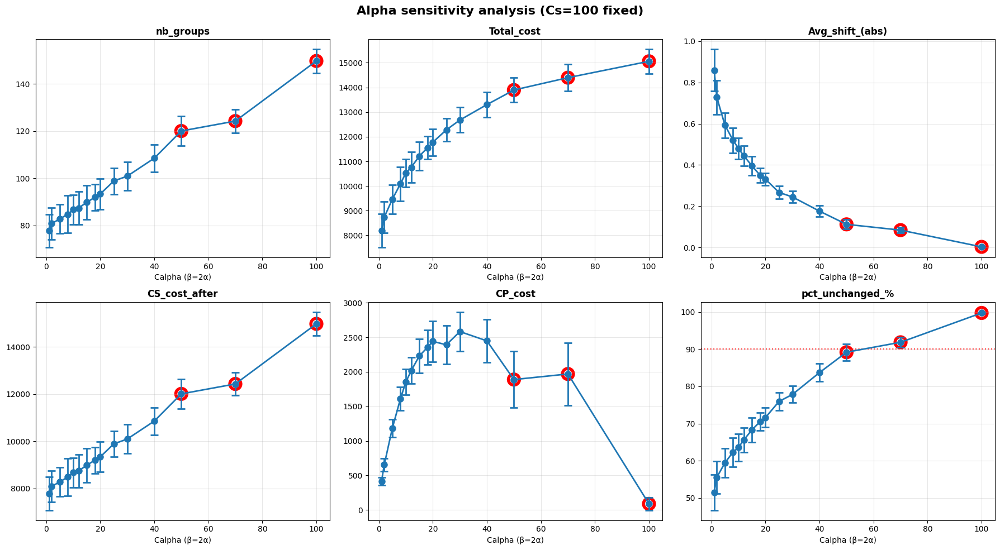

✅ 6指标完整趋势图已保存！


In [2]:
key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 
               'CS_cost_after', 'CP_cost', 'pct_unchanged_%']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Alpha sensitivity analysis (Cs=100 fixed)', 
             fontsize=16, fontweight='bold')

# 🔥 异常alpha列表
abnormal_alphas = [50, 70, 100]

for i, metric in enumerate(key_metrics):
    row = i // 3  # 0,0,0,1,1,1
    col = i % 3   # 0,1,2,0,1,2
    
    # 计算summary
    summary = summary_df.groupby('Calpha')[metric].agg(['mean', 'std']).reset_index()
    
    # 画均值线 + 误差带
    axes[row, col].errorbar(summary['Calpha'], summary['mean'], 
                           yerr=summary['std'], fmt='o-', linewidth=2, 
                           capsize=5, capthick=2, markersize=8)
    
    # 🔥 标记异常点
    for alpha in abnormal_alphas:
        if alpha in summary['Calpha'].values:
            idx = summary[summary['Calpha']==alpha].index[0]
            axes[row, col].scatter(alpha, summary.loc[idx, 'mean'], 
                                 s=200, facecolors='none', edgecolors='red', 
                                 linewidth=4)
    
    axes[row, col].set_title(f'{metric}', fontweight='bold')
    axes[row, col].set_xlabel('Calpha (β=2α)')
    axes[row, col].grid(True, alpha=0.3)
    
    # # 🔥 第6图特殊处理：参考线
    if metric == 'pct_unchanged_%':
    #     axes[row, col].axhline(y=50, color='orange', linestyle='--', alpha=0.7, label='normal')
        axes[row, col].axhline(y=90, color='red', linestyle=':', alpha=0.8, label='non-moved')
    #     axes[row, col].legend()
    #     axes[row, col].set_ylabel('Pct non-moved %')

plt.tight_layout()
plt.subplots_adjust(top=0.92)

plt.savefig('sensitivity_alpha_fixedCs/alpha_sensitivity_6metrics.png', 
            dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ 6指标完整趋势图已保存！")


In [3]:
# plus de points
# sensitivity for alpha: P=100, T=180
import os

import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time


def generate_maintenance_plan(N, T, random_seed, alpha_range=(0.001, 0.01), initial_p_range=(3.2, 3.5)):
    """生成维护计划（保持不变）"""
    caissons = [i for i in range(N)]
    
    random.seed(random_seed)
    alpha_values = [round(random.uniform(*alpha_range), 6) for _ in range(N)]
    
    random.seed(random_seed+1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values

# 🔥 🔥 🔥 从代码2复制的核心函数：计算维修周期
def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """从代码2复制：extract maintenance periods from data"""
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 =====")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

# 🔥 🔥 🔥 从代码2复制的核心聚类函数（完全替换）
def clustering_CR(df_window, window_size, window_start, global_task_count=None, full_df=None, D_min_dict=None, D_max_dict=None):
    """代码2的Gurobi版本 - 完全替换原函数"""
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 任务分配约束
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # 容量约束
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # 时间窗口约束
    a = [0] * N
    b = [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])-2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

    # 聚类激活约束
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # 🔥 关键差异1：新的目标函数（最大化利润 = setup_cost - CP_total）
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    
    # CP成本矩阵
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['Cbeta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['Calpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    obj = setup_cost - CP_total  # 🔥 最大化利润
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # 🔥 关键差异2：新增维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            
            prev_rows = full_df[
                (full_df['CSEM'] == caisson) &
                (full_df['CENTER'] < row['DATE']) &
                (full_df['OPERATION'] == 'x')
            ].sort_values('CENTER')
            
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # 求解参数
    mdl.setParam('LogToConsole', 1)
    mdl.setParam('OutputFlag', 1)
    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    # 结果提取
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].x
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal}")
    return df_window

# 🔥 保持原有的泄漏计算函数不变
def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
            
        alpha = alpha_values[int(csem)]

        # 任务间泄漏
        for i in range(1, len(x_operations)):
            current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
            prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
            center_diff = current_time - prev_time - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']

        # 开头泄漏
        first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
        total_leakage += first_time * alpha * PARAMS['K']

        # 结尾泄漏
        last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
        leak_time = max(0, T - (last_time + 1))
        total_leakage += leak_time * alpha * PARAMS['K']
    return total_leakage

def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time (使用代码2的逻辑）"""
    for caisson in clustered_df["CSEM"].unique():
        # 当前 caisson 在当前窗口内的 x 任务
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        if len(tasks) > 1:
            # 第二个任务的 index（保持代码2逻辑）
            second_idx = tasks.index[1]
            
            # 该 caisson 在本窗口聚类后的中心时间
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # 按代码2方式计算新的日期
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            
            # 同时更新 DATE 和 CENTER
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date


# 🔥 主函数修改：集成代码2逻辑
def run_clustering_analysis(params, random_seed):
    """完整聚类分析函数 - 修改版"""
    global alpha_values, PARAMS  # 确保全局变量同步
    PARAMS.update(params)
    
    # 生成维护计划
    df, alpha_values_list = generate_maintenance_plan(
        N=params['P'], T=params['T'], random_seed=random_seed
    )
    alpha_values = {i: alpha_values_list[i] for i in range(params['P'])}
    
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # 🔥 新增：计算维修周期约束（代码2特性）
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # CPU时间测量
    clustering_cpu_start = time.process_time()
    
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # 🔥 使用新的clustering_CR（带维护约束）
        clustered_df = clustering_CR(
            first_tasks, window_size, window_start, 
            full_df=df, D_min_dict=D_min_dict, D_max_dict=D_max_dict
        )
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑（保持不变）
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏（保持不变）
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }

def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,
        # 'CS_cost_reduction': cs_cost_reduction,
        # 'CS_cost_reduction_pct': cs_cost_reduction_pct,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats


def run_analysis_with_csv_export(params, seeds, output_filename='detailed_results.csv'):
    """
    运行多种子分析并导出完整CSV（包含所有表格列）
    """
    all_results = []
    
    for seed in seeds:
        print(f"\n🔄 Processing seed {seed}...")
        
        # 运行分析
        result_dict = run_clustering_analysis(params, random_seed=seed)
        
        # 计算详细统计
        stats = calculate_detailed_stats(result_dict, params)
        stats['seed'] = seed  # 填充seed信息
        
        all_results.append(stats)
        
        # 打印摘要
        print(f"✅ Seed {seed}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
    
    # 转换为DataFrame并排序列顺序（匹配你的表格）
    results_df = pd.DataFrame(all_results)
    
    # 按你的截图调整列顺序
    column_order = [
        'seed', 'nb_groups', 'Avg_tasks/group',  'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost',
        'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)','pct_advanced_%', 
        'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 只保留存在的列并排序
    available_columns = [col for col in column_order if col in results_df.columns]
    results_df = results_df[available_columns]
    
    # 保存CSV
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 完整结果已保存到: {output_filename}")
    print(f"📊 包含 {len(results_df)} 种子, {len(results_df.columns)} 个指标列")
    
    return results_df


def visualize_clustering_results(result_dict, params, seed_name="default", save_csv=True, show_plot=True):
    """可视化聚类结果"""
    result_df = result_dict['final_df']
    maintenance_plan = result_dict['maintenance_plan']
    
    # 成本计算
    operation_x_count = (result_df['OPERATION'] == 'x').sum()
    before_cost = operation_x_count * params['Cs'] 
    operation_x_center_unique_count = result_df[result_df['OPERATION'] == 'x']['CENTER'].nunique()
    after_cost = operation_x_center_unique_count * params['Cs'] 
    
    print(f"Cost before grouping: {before_cost}")
    print(f"Cost after grouping: {after_cost}")
    
    # 泄漏统计
    leakage_before = round(result_dict['leakage_before'], 3)
    leakage_after = round(result_dict['leakage_after'], 3)
    print(f"Gas leakage before: {leakage_before}")
    print(f"Gas leakage after: {leakage_after}")
    
    # 节约统计
    cost_reduction = before_cost - after_cost
    cost_reduction_pct = (cost_reduction / before_cost * 100) if before_cost > 0 else 0
    print(f"Cost reduction: {cost_reduction} ({cost_reduction_pct:.1f}%)")
    print(f"Gas leakage reduction: {result_dict['reduction']:.3f} ({result_dict['reduction_pct']:.1f}%)")
    
    # 计算统计指标（修复UnboundLocalError）
    result_df_x_count = len(result_df[result_df['OPERATION'] == 'x'])
    avg_tasks_per_cluster = result_df_x_count / operation_x_center_unique_count if operation_x_center_unique_count > 0 else 0
    
    if show_plot:
        plt.figure(figsize=(8, 7))
        
        df_original_x = maintenance_plan[maintenance_plan['OPERATION'] == 'x']
        result_df_x = result_df[result_df['OPERATION'] == 'x']
        
        df_x = df_original_x.set_index('INDEX')
        result_x = result_df_x.set_index('INDEX')
        common_indices = df_x.index.intersection(result_x.index)
        df_x = df_x.loc[common_indices].reset_index()
        result_x = result_x.loc[common_indices].reset_index()
        
        time_shift = result_x['CENTER'] - df_x['DATE']
        plt.scatter(df_x['DATE'], result_x['CENTER'], 
                   c=time_shift, cmap='RdBu_r', 
                   vmin=-max(abs(time_shift.min()), abs(time_shift.max())), 
                   vmax=max(abs(time_shift.min()), abs(time_shift.max())), 
                   alpha=0.7, s=50, edgecolors='black', linewidth=0.8)
        
        plt.colorbar(label='Time Shift (days)\nRed=delayed, Blue=advanced')
        plt.title(f"Cluster Center Distribution (Seed {seed_name})", fontsize=16, fontweight='bold')
        plt.xlabel("Original time", fontsize=14)
        plt.ylabel("Cluster center", fontsize=14)
        plt.grid(True, alpha=0.3)
        
        max_range = max(result_x['DATE'].max(), result_x['CENTER'].max() + 5)
        plt.xlim(0, max_range)
        plt.ylim(0, max_range)
        plt.plot([0, max_range], [0, max_range], color='gray', linestyle='--', linewidth=2, label='45° diagonal')
        plt.legend()
        plt.gca().set_aspect('equal')
        plt.tight_layout()
        plt.show()
        
        center_counts = result_df_x['CENTER'].value_counts().sort_index()
        print("\nCluster center usage:")
        print(center_counts)
        print(f"Total clusters used: {len(center_counts)}")
        print(f"Average tasks per cluster: {avg_tasks_per_cluster:.1f}")
    
    if save_csv:
        filename = f'optimized_plan_seed_{seed_name}.csv'
        result_df.to_csv(filename, index=False)
        print(f"\nResult saved to '{filename}'")
    
    print(f"\nSummary:")
    print(f"- Cost saved: {cost_reduction_pct:.1f}%")
    print(f"- Gas leakage reduced: {result_dict['reduction_pct']:.1f}%")
    print(f"- Clusters created: {operation_x_center_unique_count}")


    return {
        'before_cost': before_cost,
        'after_cost': after_cost,
        'cost_reduction': cost_reduction,
        'cost_reduction_pct': cost_reduction_pct,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'clusters_used': operation_x_center_unique_count,
        'avg_tasks_per_cluster': avg_tasks_per_cluster
    }




# 🔥 你的核心参数（固定P,T, Cs）
PARAMS = {
    'P': 100, 
    'T': 180,  # 或你想测试的T
    'Cmax': 10, 
    'window_size': 10, 
    'advanced': 3, 
    'K': 5.993, 
    'Cs': 100,  # 🔥 固定Cs
    'x_days': 3  # 或你喜欢的
}

# 🔥 要测试的alpha范围（你根据经验调整）
alpha_list = [1, 2, 5, 8, 10, 12, 15, 18, 20, 25, 30, 40, 50, 60, 70, 90, 100]  # 从1到100的多个alpha值
seeds_per_alpha = list(range(1, 11))  # 每alpha跑5个seed

# 创建输出目录
os.makedirs('sensitivity_alpha_fixedCs_morePoints', exist_ok=True)

all_results = []

print("🔄 开始 alpha 敏感性分析 (Cs=100固定)")
for alpha in alpha_list:
    print(f"\n--- alpha={alpha} ---")
    
    # 设置参数（beta=2*alpha）
    params = PARAMS.copy()
    params['Calpha'] = alpha
    params['Cbeta'] = 2 * alpha
    
    # 跑多种子实验
    filename = f"sensitivity_alpha_fixedCs_morePoints/alpha_{alpha}_Cs100.csv"
    result_df = run_analysis_with_csv_export(params, seeds_per_alpha, output_filename=filename)
    
    # 加参数列
    result_df['Calpha'] = alpha
    result_df['Cbeta'] = 2 * alpha
    result_df['Cs'] = params['Cs']
    
    all_results.append(result_df)

# 🔥 汇总大表
summary_df = pd.concat(all_results, ignore_index=True)
summary_df.to_csv('sensitivity_alpha_fixedCs_morePoints/summary_alpha_fixedCs100.csv', index=False)
print("\n✅ 大汇总表已保存：sensitivity_alpha_fixedCs_morePoints/summary_alpha_fixedCs100.csv")

# 🔥 自动生成关键指标的平均表
key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)']
summary_table = summary_df.groupby('Calpha')[key_metrics].agg(['mean', 'std']).round(2)
print("\n📊 关键指标汇总表：")
print(summary_table)


🔄 开始 alpha 敏感性分析 (Cs=100固定)

--- alpha=1 ---

🔄 Processing seed 1...
Generated 331 tasks for seed 1

===== 从数据中提取维修周期 =====
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 10.00        ...
1          4          [35, 35]             35.00        21         49        
2          4          [39, 39]             39.00        24         55        
3          1          [92, 92]             92.00        56         129       
4          2          [55, 55]             55.00        33         77        
5          2          [60, 60]             60.00        36         84        
6          3          [44, 44]             44.00        27         62        
7          4          [38, 38]             38.00        23         54        
8          ... 10.00        ...
9          ... 10.00        ...
10         4          [36, 36]             36.00        22         51      

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 70: N_tasks=19
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 504 rows, 231 columns and 1597 nonzeros
Model fingerprint: 0x21f9421b
Variable types: 11 continuous, 220 integer (220 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [8e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 4e+01]
Presolve removed 439 rows and 62 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 70: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to valu

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Solution count 5: 1771 1684 1670 ... 1085

Optimal solution found (tolerance 5.00e-02)
Best objective 1.771000000000e+03, best bound 1.774000000000e+03, gap 0.1694%
Model stats: 242 vars, 533 cons
Objective value: 1771.0
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 160: N_tasks=26
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 681 rows, 308 columns and 2212 nonzeros
Model fingerprint: 0xc2d5a5ea
Variable types: 11 continuous, 297 integer (297 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [8e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Presolve removed 599 rows and 78 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available 

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

... (985 outputs left out)

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 130: N_tasks=23
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 608 rows, 275 columns and 1977 nonzeros
Model fingerprint: 0x6dab567f
Variable types: 11 continuous, 264 integer (264 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+02, 2e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]
Found heuristic solution: objective -10500.00000
Presolve removed 563 rows and 67 columns
Presolve time: 0.00s
Presolved: 45 rows, 208 columns, 613 nonzeros
Variable types: 0 continuous, 208 integer (208 binary)
Found heuristic solution: objective 1200.0000000

Root relaxation: objective 2.068889e+03, 0 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objec

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_58692/1956032799.py:297: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals



📁 完整结果已保存到: sensitivity_alpha_fixedCs_morePoints/alpha_100_Cs100.csv
📊 包含 10 种子, 19 个指标列

✅ 大汇总表已保存：sensitivity_alpha_fixedCs_morePoints/summary_alpha_fixedCs100.csv

📊 关键指标汇总表：
       nb_groups       Total_cost         Avg_shift_(abs)      
            mean   std       mean     std            mean   std
Calpha                                                         
1           78.3  6.83     8235.5  655.01            0.84  0.09
2           81.5  8.00     8803.6  744.84            0.72  0.10
5           82.9  6.47     9500.0  627.72            0.60  0.06
8           86.2  6.99    10224.8  595.75            0.51  0.06
10          87.0  5.37    10573.0  501.38            0.48  0.06
12          89.4  6.50    10932.0  571.64            0.43  0.05
15          91.4  6.74    11364.5  568.94            0.39  0.05
18          91.0  5.50    11540.8  411.30            0.36  0.04
20          92.3  4.45    11726.0  454.61            0.33  0.03
25          98.8  3.71    12282.5  396.17           

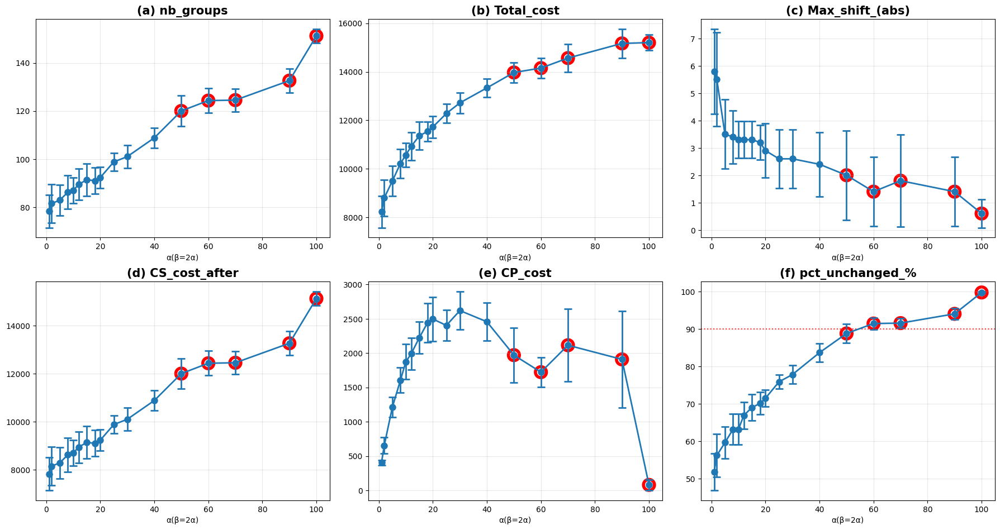

✅ 6指标完整趋势图已保存！


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

summary_df = pd.read_csv('sensitivity_alpha_fixedCs_morePoints/summary_alpha_fixedCs100.csv')

# key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 
#                'CS_cost_after', 'CP_cost', 'pct_unchanged_%']

key_metrics = ['nb_groups', 'Total_cost', 'Max_shift_(abs)', 
               'CS_cost_after', 'CP_cost', 'pct_unchanged_%']
subplot_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']  # 6个子图标签


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# fig.suptitle('Alpha sensitivity analysis (Cs=100 fixed)', 
#              fontsize=16, fontweight='bold')

# 🔥 异常alpha列表
abnormal_alphas = [50, 60, 70, 90, 100]

for i, (metric, label) in enumerate(zip(key_metrics, subplot_labels)):
    row = i // 3  # 0,0,0,1,1,1
    col = i % 3   # 0,1,2,0,1,2
    
    # 计算summary
    summary = summary_df.groupby('Calpha')[metric].agg(['mean', 'std']).reset_index()
    
    # 画均值线 + 误差带
    axes[row, col].errorbar(summary['Calpha'], summary['mean'], 
                           yerr=summary['std'], fmt='o-', linewidth=2, 
                           capsize=5, capthick=2, markersize=8)
    
    # 🔥 标记异常点
    for alpha in abnormal_alphas:
        if alpha in summary['Calpha'].values:
            idx = summary[summary['Calpha']==alpha].index[0]
            axes[row, col].scatter(alpha, summary.loc[idx, 'mean'], 
                                 s=200, facecolors='none', edgecolors='red', 
                                 linewidth=4)
    
    axes[row, col].set_title(f'{label} {metric}', fontweight='bold', fontsize=15)
    axes[row, col].set_xlabel('α (β=2α)')
    axes[row, col].grid(True, alpha=0.3)
    
    # # 🔥 第6图特殊处理：参考线
    if metric == 'pct_unchanged_%':
    #     axes[row, col].axhline(y=50, color='orange', linestyle='--', alpha=0.7, label='normal')
        axes[row, col].axhline(y=90, color='red', linestyle=':', alpha=0.8, label='non-moved')
    #     axes[row, col].legend()
    #     axes[row, col].set_ylabel('Pct non-moved %')

plt.tight_layout()
plt.subplots_adjust(top=0.92)

# plt.savefig('sensitivity_alpha_fixedCs_morePoints/alpha_sensitivity_6metrics.png', 
#             dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ 6指标完整趋势图已保存！")


🔄 开始 beta倍数敏感性分析 (alpha=10固定, beta_base=10)

--- beta_multiplier=0.1, beta=1.0 ---

🔄 Processing seed 1...
Generated 331 tasks for seed 1

===== 从数据中提取维修周期 ===
Caisson    间隔数        间隔范围                 周期           D_min      D_max     
--------------------------------------------------------------------------------
0          ... 7.00         ...
1          4          [35, 35]             35.00        21         49        
2          4          [39, 39]             39.00        24         55        
3          1          [92, 92]             92.00        56         129       
4          2          [55, 55]             55.00        33         77        
5          2          [60, 60]             60.00        36         84        
6          3          [44, 44]             44.00        27         62        
7          4          [38, 38]             38.00        23         54        
8          ... 7.00         ...
9          ... 7.00         ...
10         4          [36, 36]         

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 49: N_tasks=20
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 392 rows, 176 columns and 1152 nonzeros
Model fingerprint: 0x19549df8
Variable types: 8 continuous, 168 integer (168 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [3e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+01]
Presolve removed 349 rows and 46 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 49: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 105: N_tasks=11
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 231 rows, 104 columns and 673 nonzeros
Model fingerprint: 0x59485ed3
Variable types: 8 continuous, 96 integer (96 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [3e+01, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 7e+01]
Presolve removed 186 rows and 8 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 105: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

... (2,202 outputs left out)

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 119: N_tasks=11
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 233 rows, 104 columns and 687 nonzeros
Model fingerprint: 0xda04deee
Variable types: 8 continuous, 96 integer (96 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [3e+01, 6e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 6e+01]
Presolve removed 200 rows and 24 columns
Presolve time: 0.00s

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 0
No other solutions better than -1e+100

Model is infeasible
Best objective -, best bound -, gap -
Failed to solve window 119: 3
Set parameter OutputFlag to value 1
Set parameter TimeLimit to value 300
Set parameter MIPGap to value 

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

Set parameter TimeLimit to value 300
Set parameter MIPGap to value 0.05
Window 161: N_tasks=12
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 252 rows, 112 columns and 748 nonzeros
Model fingerprint: 0xf5150169
Variable types: 8 continuous, 104 integer (104 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [3e+01, 5e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+01]
Found heuristic solution: objective -250.0000000
Presolve removed 224 rows and 25 columns
Presolve time: 0.00s
Presolved: 28 rows, 87 columns, 253 nonzeros
Variable types: 0 continuous, 87 integer (87 binary)
Found heuristic solution: objective 590.0000000

Root relaxation: objective 1.078333e+03, 12 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl 

/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])
/var/folders/08/0s62qkn131s4xxtxmk7knl840000gp/T/ipykernel_68221/3085036920.py:290: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  first_tasks = window_df.groupby('CSEM', group_keys=Fals

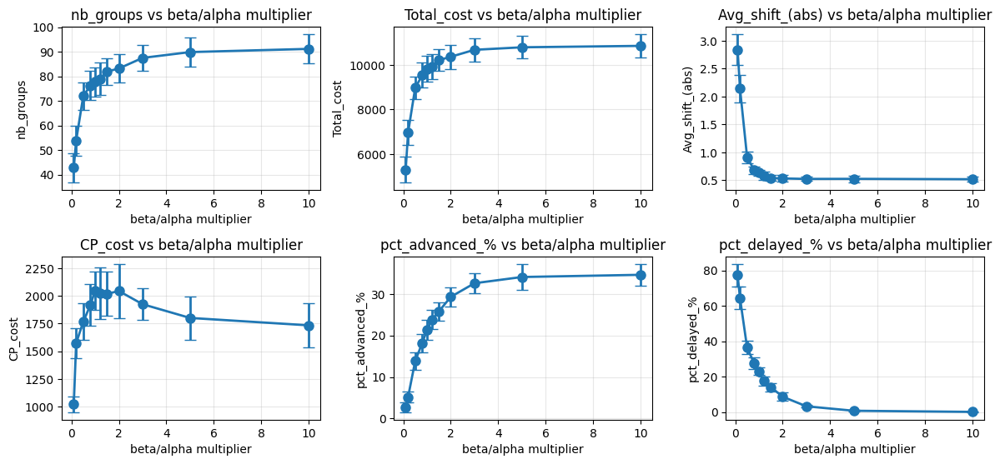


🎉 beta倍数敏感性分析完成！
   alpha基准值: 10
   beta基准值: 10
   测试倍数范围: 0.1 - 10.0
   输出目录: sensitivity_beta_multiplier_alpha10/


In [1]:
# plus de points
# sensitivity for beta as multiple of alpha: P=100, T=180, beta_base=10
import os
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
import random
import matplotlib.pyplot as plt
import time

def generate_maintenance_plan(N, T, random_seed, alpha_range=(0.001, 0.01), initial_p_range=(3.2, 3.5)):
    """生成维护计划（保持不变）"""
    caissons = [i for i in range(N)]
    
    random.seed(random_seed)
    alpha_values = [round(random.uniform(*alpha_range), 6) for _ in range(N)]
    
    random.seed(random_seed+1)
    initial_p_values = [round(random.uniform(*initial_p_range), 2) for _ in range(N)]
    
    columns = ['INDEX', 'CSEM', 'INITIALP', 'OPERATION', 'DATE']
    data = []
    
    index = 0
    for caisson in range(N):
        current_p = initial_p_values[caisson]
        total_days = 0
        alpha = alpha_values[caisson]
        
        while total_days < T:
            time_to_3_2 = int((current_p - 3.2) / alpha)
            if total_days + time_to_3_2 >= T:
                break
            
            operation = 'x'
            data.append([index, caisson, initial_p_values[caisson], operation, total_days + time_to_3_2])
            index += 1
            total_days += time_to_3_2 + 1
            current_p = 3.5
    
    maintenance_plan = pd.DataFrame(data, columns=columns)
    return maintenance_plan, alpha_values

def calculate_maintenance_period_from_data(df, d_min_ratio=0.6, d_max_ratio=1.4):
    """从代码2复制：extract maintenance periods from data"""
    maintenance_periods = {}
    D_min_dict = {}
    D_max_dict = {}
    
    print("\n===== 从数据中提取维修周期 ===")
    print(f"{'Caisson':<10} {'间隔数':<10} {'间隔范围':<20} {'周期':<12} {'D_min':<10} {'D_max':<10}")
    print("-" * 80)
    
    for caisson_id in sorted(df['CSEM'].unique()):
        caisson_tasks = df[(df['CSEM'] == caisson_id) & (df['OPERATION'] == 'x')].sort_values('DATE')
        
        if len(caisson_tasks) < 2:
            default_period = PARAMS['window_size']
            maintenance_periods[caisson_id] = default_period
            D_min_dict[caisson_id] = int(np.ceil(default_period * d_min_ratio))
            D_max_dict[caisson_id] = int(np.ceil(default_period * d_max_ratio))
            print(f"{caisson_id:<10} ... {default_period:<12.2f} ...")  
            continue
        
        intervals = []
        for i in range(1, len(caisson_tasks)):
            interval = caisson_tasks.iloc[i]['DATE'] - caisson_tasks.iloc[i-1]['DATE']
            intervals.append(interval)
        
        maintenance_period = np.mean(intervals)
        maintenance_periods[caisson_id] = maintenance_period
        D_min_dict[caisson_id] = int(np.ceil(maintenance_period * d_min_ratio))
        D_max_dict[caisson_id] = int(np.ceil(maintenance_period * d_max_ratio))
        
        interval_min = min(intervals)
        interval_max = max(intervals)
        interval_range = f"[{interval_min}, {interval_max}]"
        
        print(f"{caisson_id:<10} {len(intervals):<10} {interval_range:<20} "
              f"{maintenance_period:<12.2f} {D_min_dict[caisson_id]:<10} {D_max_dict[caisson_id]:<10}")
    
    print("===== 提取完成 =====\n")
    return maintenance_periods, D_min_dict, D_max_dict

def clustering_CR(df_window, window_size, window_start, global_task_count=None, full_df=None, D_min_dict=None, D_max_dict=None):
    """代码2的Gurobi版本 - 完全替换原函数"""
    if df_window.empty or window_size < 1:
        print(f"warning: window {window_start} has no tasks")
        return df_window

    N = df_window.shape[0]
    mdl = gp.Model('Dynamic_Window_Clustering')
    mdl.setParam('OutputFlag', 0)

    data_pos_num = window_size + 1
    theta = mdl.addVars(N, data_pos_num, vtype=GRB.BINARY, name='theta')
    CS = mdl.addVars(data_pos_num, lb=0.0, vtype=GRB.CONTINUOUS, name='CS')
    y = mdl.addVars(data_pos_num, vtype=GRB.BINARY, name='y')

    # 任务分配约束
    for n in range(N):
        mdl.addConstr(theta.sum(n, '*') == 1, name=f"assign_task_{n}")

    # 容量约束
    for t in range(data_pos_num):
        mdl.addConstr(theta.sum('*', t) <= PARAMS['Cmax'], name=f"cap_{t}")

    # 时间窗口约束
    a = [0] * N
    b = [0] * N
    for n in range(N):
        local_time = int(df_window.iloc[n]['window_time'])
        a[n] = int(max(0, local_time - PARAMS['advanced']))
        b[n] = int(min(data_pos_num, local_time + int((3.2 - 3.0)/alpha_values[int(df_window.iloc[n]["CSEM"])])-2))

    for n in range(N):
        for t in range(data_pos_num):
            mdl.addConstr(t * theta[n, t] + a[n] * (1 - theta[n, t]) >= a[n], name=f"lb_range_n{n}_t{t}")
            mdl.addConstr(t * theta[n, t] + b[n] * (1 - theta[n, t]) <= b[n], name=f"ub_range_n{n}_t{t}")

    # 聚类激活约束
    M = PARAMS['Cmax']
    for t in range(data_pos_num):
        task_count = theta.sum('*', t)
        mdl.addConstr(task_count + M * (1 - y[t]) >= 1, name=f"activate_lb_{t}")
        mdl.addConstr(task_count <= M * y[t], name=f"activate_ub_{t}")

    # 🔥 关键差异1：新的目标函数（最大化利润 = setup_cost - CP_total）
    setup_cost = PARAMS['Cs'] * (theta.sum() - y.sum())
    
    # CP成本矩阵
    cost_matrix = {}
    for n in range(N):
        local_time_n = int(df_window.iloc[n]['window_time'])
        for t in range(data_pos_num):
            deviation = t - local_time_n
            if deviation > 0:
                cost_matrix[(n, t)] = PARAMS['Cbeta'] * deviation
            elif deviation < 0:
                cost_matrix[(n, t)] = PARAMS['Calpha'] * (-deviation)
            else:
                cost_matrix[(n, t)] = 0
    
    CP_total = gp.quicksum(cost_matrix[(n, t)] * theta[n, t] for n in range(N) for t in range(data_pos_num))
    obj = setup_cost - CP_total  # 🔥 最大化利润
    mdl.setObjective(obj, GRB.MAXIMIZE)

    # 🔥 关键差异2：新增维护间隔约束
    if window_start > 0 and full_df is not None and D_min_dict is not None:
        for n in range(N):
            row = df_window.iloc[n]
            caisson = int(row['CSEM'])
            
            prev_rows = full_df[
                (full_df['CSEM'] == caisson) &
                (full_df['CENTER'] < row['DATE']) &
                (full_df['OPERATION'] == 'x')
            ].sort_values('CENTER')
            
            if not prev_rows.empty:
                prev_center = int(prev_rows.iloc[-1]['CENTER'])
                t_now_local = gp.quicksum(t * theta[n, t] for t in range(data_pos_num))
                d_min_i = D_min_dict.get(caisson, PARAMS['window_size'] * 0.6)
                d_max_i = D_max_dict.get(caisson, PARAMS['window_size'] * 1.4)
                
                mdl.addConstr(t_now_local + window_start - prev_center >= d_min_i, name=f"dmin_n{n}")
                mdl.addConstr(t_now_local + window_start - prev_center <= d_max_i, name=f"dmax_n{n}")

    # 求解参数
    mdl.setParam('LogToConsole', 1)
    mdl.setParam('OutputFlag', 1)
    mdl.setParam('TimeLimit', 300)
    mdl.setParam('MIPGap', 0.05)

    print(f"Window {window_start}: N_tasks={N}")
    mdl.optimize()

    if mdl.status not in [GRB.OPTIMAL, GRB.TIME_LIMIT, GRB.SUBOPTIMAL]:
        print(f"Failed to solve window {window_start}: {mdl.status}")
        return None
    
    # 结果提取
    centers = {}
    for n in range(N):
        for t in range(data_pos_num):
            val = theta[n, t].x
            if val is not None and round(val) == 1:
                centers[n] = t + window_start
                break

    index_n_list = df_window.INDEX.tolist()
    for n in range(len(index_n_list)):
        df_window.loc[df_window['INDEX'] == index_n_list[n], 'CENTER'] = centers.get(n, 0)

    print(f"Model stats: {mdl.NumVars} vars, {mdl.NumConstrs} cons")
    print(f"Objective value: {mdl.ObjVal}")
    return df_window

def calculate_gas_leakage(df, T, use_center=True):
    total_leakage = 0
    for csem in df['CSEM'].unique():
        csem_data = df[df['CSEM'] == csem]
        x_operations = csem_data[csem_data['OPERATION'] == 'x'].sort_values('DATE' if not use_center else 'CENTER')
        if x_operations.empty:
            continue
            
        alpha = alpha_values[int(csem)]

        # 任务间泄漏
        for i in range(1, len(x_operations)):
            current_time = x_operations.iloc[i][('CENTER' if use_center else 'DATE')]
            prev_time = x_operations.iloc[i-1][('CENTER' if use_center else 'DATE')]
            center_diff = current_time - prev_time - 1
            total_leakage += max(0, center_diff) * alpha * PARAMS['K']

        # 开头泄漏
        first_time = x_operations.iloc[0][('CENTER' if use_center else 'DATE')]
        total_leakage += first_time * alpha * PARAMS['K']

        # 结尾泄漏
        last_time = x_operations.iloc[-1][('CENTER' if use_center else 'DATE')]
        leak_time = max(0, T - (last_time + 1))
        total_leakage += leak_time * alpha * PARAMS['K']
    return total_leakage

def update_secondary_tasks(main_df, clustered_df, window_start, window_end):
    """Update the secondary tasks time (使用代码2的逻辑）"""
    for caisson in clustered_df["CSEM"].unique():
        # 当前 caisson 在当前窗口内的 x 任务
        tasks = main_df[
            (main_df['CSEM'] == caisson) & 
            (main_df['DATE'].between(window_start, window_end)) & 
            (main_df['OPERATION'] == 'x')
        ].sort_values('DATE')
        
        if len(tasks) > 1:
            # 第二个任务的 index（保持代码2逻辑）
            second_idx = tasks.index[1]
            
            # 该 caisson 在本窗口聚类后的中心时间
            center_time = clustered_df.loc[clustered_df['CSEM'] == caisson, 'CENTER'].iloc[0]
            
            # 按代码2方式计算新的日期
            alpha = alpha_values[int(caisson)]
            new_date = int(center_time + 1 + (3.5 - 3.2) / alpha)
            
            # 同时更新 DATE 和 CENTER
            main_df.loc[second_idx, ['DATE', 'CENTER']] = new_date, new_date

def run_clustering_analysis(params, random_seed):
    """完整聚类分析函数 - 修改版"""
    global alpha_values, PARAMS  # 确保全局变量同步
    PARAMS.update(params)
    
    # 生成维护计划
    df, alpha_values_list = generate_maintenance_plan(
        N=params['P'], T=params['T'], random_seed=random_seed
    )
    alpha_values = {i: alpha_values_list[i] for i in range(params['P'])}
    
    print(f"Generated {len(df)} tasks for seed {random_seed}")
    
    # 🔥 新增：计算维修周期约束（代码2特性）
    maintenance_periods, D_min_dict, D_max_dict = calculate_maintenance_period_from_data(df)
    
    # CPU时间测量
    clustering_cpu_start = time.process_time()
    
    df_init = df.copy()
    df_history_list = [df_init]
    sliding_windows_starts = []
    sliding_windows_ends = []
    df['CENTER'] = df['DATE']
    
    window_start = 0
    window_size = params['window_size']
    
    while window_start <= params['T']:
        window_end = min(window_start + window_size, params['T'])
        sliding_windows_starts.append(window_start)
        sliding_windows_ends.append(window_end)
        
        mask = (df['DATE'] >= window_start) & (df['DATE'] <= window_end) & (df['OPERATION']== 'x')
        window_df = df.loc[mask].copy()
        if window_df.empty:
            break
            
        window_df['window_time'] = window_df['DATE'] - window_start
        first_tasks = window_df.groupby('CSEM', group_keys=False).apply(lambda x: x.sort_values('DATE').iloc[0])

        # 🔥 使用新的clustering_CR（带维护约束）
        clustered_df = clustering_CR(
            first_tasks, window_size, window_start, 
            full_df=df, D_min_dict=D_min_dict, D_max_dict=D_max_dict
        )
        
        if clustered_df is not None:
            center_map = clustered_df.set_index('INDEX')['CENTER']
            df.loc[df['INDEX'].isin(center_map.index), 'CENTER'] = df['INDEX'].map(center_map)
            update_secondary_tasks(df, clustered_df, window_start, window_end)
        
        # 滑动窗口逻辑（保持不变）
        second_dates = []
        if clustered_df is not None:
            for caisson in clustered_df["CSEM"].unique():
                tasks = df[(df['CSEM'] == caisson) & 
                          (df['OPERATION'] == 'x') &
                          (df['DATE'].between(window_start, window_end))].sort_values('DATE')
                if len(tasks) > 1:
                    second_dates.append(tasks.iloc[1]['DATE'])
        
        window_start = min(second_dates) if second_dates else window_start + window_size
        df_history_list.append(df.copy())
        
        if window_end >= params['T']:
            break
    
    # 处理未分配任务
    mask_remain = (df['OPERATION'] == "x") & (df['CENTER'] == df['DATE'])
    df.loc[mask_remain, 'CENTER'] = df.loc[mask_remain, 'DATE']

    clustering_cpu_end = time.process_time()
    total_clustering_cpu_time = clustering_cpu_end - clustering_cpu_start

    # 计算泄漏（保持不变）
    leakage_before = calculate_gas_leakage(df_init, params['T'], use_center=False)
    leakage_after = calculate_gas_leakage(df, params['T'], use_center=True)
    reduction = leakage_before - leakage_after
    reduction_pct = (reduction / leakage_before * 100) if leakage_before > 0 else 0
    
    return {
        'final_df': df,
        'df_history_list': df_history_list,
        'sliding_windows_starts': sliding_windows_starts,
        'sliding_windows_ends': sliding_windows_ends,
        'alpha_values': alpha_values_list,
        'maintenance_plan': df_init,
        'D_min_dict': D_min_dict,
        'D_max_dict': D_max_dict,
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'reduction': reduction,
        'reduction_pct': reduction_pct,
        'total_clustering_cpu_time': total_clustering_cpu_time
    }

def calculate_detailed_stats(result_dict, params):
    """
    计算所有详细指标，用于CSV输出
    """
    df_orig = result_dict['maintenance_plan'].copy()
    result_df = result_dict['final_df'].copy()
    
    # 只针对x任务，确保INDEX对齐
    df_x = df_orig[df_orig['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    res_x = result_df[result_df['OPERATION'] == 'x'].sort_values('INDEX').reset_index(drop=True)
    
    # CP成本计算
    time_diffs = res_x['CENTER'].values - df_x['DATE'].values
    cp_cost = np.sum(
        np.where(time_diffs < 0, np.abs(time_diffs) * params['Calpha'], time_diffs * params['Cbeta'])
    )
    
    # 聚类统计
    center_counts = res_x['CENTER'].value_counts()
    num_groups = len(center_counts)
    avg_tasks_per_group = center_counts.mean()
    
    # 时间偏移统计
    num_tasks = len(time_diffs)
    avg_shift_abs = np.mean(np.abs(time_diffs))
    max_shift_abs = np.max(np.abs(time_diffs))
    
    # 提前统计
    advanced_mask = time_diffs < 0
    avg_advance = np.mean(np.abs(time_diffs[advanced_mask])) if np.any(advanced_mask) else 0
    num_advanced = np.sum(advanced_mask)
    pct_advanced = num_advanced / num_tasks * params['Cs']
    
    # 延迟统计
    delayed_mask = time_diffs > 0
    avg_delay = np.mean(time_diffs[delayed_mask]) if np.any(delayed_mask) else 0
    num_delayed = np.sum(delayed_mask)
    pct_delayed = num_delayed / num_tasks * params['Cs']
    
    # 不变统计
    num_unchanged = np.sum(time_diffs == 0)
    pct_unchanged = num_unchanged / num_tasks * params['Cs']
    
    # 成本统计
    operation_x_count = len(df_x)
    cs_cost_before = operation_x_count * params['Cs']
    cs_cost_after = num_groups * params['Cs']
    cs_cost_reduction = cs_cost_before - cs_cost_after
    cs_cost_reduction_pct = cs_cost_reduction / cs_cost_before * 100
    total_cost = cs_cost_after + cp_cost
    
    # 泄漏统计（来自result_dict）
    leakage_before = result_dict['leakage_before']
    leakage_after = result_dict['leakage_after']
    leakage_reduction = result_dict['reduction']
    leakage_reduction_pct = result_dict['reduction_pct']

    # 🔥 整个聚类过程CPU时间
    total_clustering_cpu_time = result_dict.get('total_clustering_cpu_time', 0)
    
    # 完整统计字典（匹配你的表格列）
    stats = {
        # 基本信息
        'seed': None,  # 稍后填充
        'nb_groups': num_groups,
        'Avg_tasks/group': avg_tasks_per_group,
        
        # CP成本
        'CP_cost': cp_cost,
        
        # 时间偏移
        'Avg_shift_(abs)': avg_shift_abs,
        'Max_shift_(abs)': max_shift_abs,
        'Avg_advance_(days)': avg_advance,
        'Avg_delay_(days)': avg_delay,
        'pct_advanced_%': pct_advanced,
        'pct_delayed_%': pct_delayed,
        'pct_unchanged_%': pct_unchanged,
        'num_advanced': num_advanced,
        'num_delayed': num_delayed,
        'num_unchanged': num_unchanged,
        'total_tasks': num_tasks,
        
        # CS成本
        'CS_cost_before': cs_cost_before,
        'CS_cost_after': cs_cost_after,

        # Total成本
        'Total_cost': total_cost,
        
        # 泄漏统计
        'leakage_before': leakage_before,
        'leakage_after': leakage_after,
        'leakage_reduction': leakage_reduction,
        'leakage_reduction_pct': leakage_reduction_pct,

        # CPU时间
        'total_clustering_cpu_s': total_clustering_cpu_time,
    }
    
    return stats

def run_analysis_with_csv_export(params, seeds, output_filename='detailed_results.csv'):
    """
    运行多种子分析并导出完整CSV（包含所有表格列）
    """
    all_results = []
    
    for seed in seeds:
        print(f"\n🔄 Processing seed {seed}...")
        
        # 运行分析
        result_dict = run_clustering_analysis(params, random_seed=seed)
        
        # 计算详细统计
        stats = calculate_detailed_stats(result_dict, params)
        stats['seed'] = seed  # 填充seed信息
        
        all_results.append(stats)
        
        # 打印摘要
        print(f"✅ Seed {seed}: CP_cost={stats['CP_cost']:.1f}, Groups={stats['nb_groups']}")
    
    # 转换为DataFrame并排序列顺序（匹配你的表格）
    results_df = pd.DataFrame(all_results)
    
    # 按你的截图调整列顺序
    column_order = [
        'seed', 'nb_groups', 'Avg_tasks/group',  'CS_cost_before', 'CS_cost_after', 'CP_cost', 'Total_cost',
        'Avg_shift_(abs)', 'Max_shift_(abs)', 'Avg_advance_(days)', 'Avg_delay_(days)','pct_advanced_%', 
        'pct_delayed_%', 'pct_unchanged_%', 'leakage_before', 'leakage_after', 'leakage_reduction', 
        'leakage_reduction_pct', 'total_clustering_cpu_s'
    ]
    
    # 只保留存在的列并排序
    available_columns = [col for col in column_order if col in results_df.columns]
    results_df = results_df[available_columns]
    
    # 保存CSV
    results_df.to_csv(output_filename, index=False, float_format='%.3f')
    print(f"\n📁 完整结果已保存到: {output_filename}")
    print(f"📊 包含 {len(results_df)} 种子, {len(results_df.columns)} 个指标列")
    
    return results_df

# 🔥 核心参数（固定P,T, Cs, alpha基准）
PARAMS = {
    'P': 100, 
    'T': 180,
    'Cmax': 20, 
    'window_size': 7, 
    'advanced': 3, 
    'K': 5.993, 
    'Cs': 100,  # 🔥 固定Cs
    'x_days': 3
}

# 🔥 beta倍数测试（beta = multiplier * alpha）
beta_multipliers = [0.1, 0.2, 0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 3.0, 5.0, 10.0]  # beta/alpha 的倍数范围
alpha_base = 10  # alpha基准值
seeds_per_multiplier = list(range(1, 31))  # 每倍数跑30个seed

# 创建输出目录
os.makedirs('sensitivity_beta_multiplier_alpha10', exist_ok=True)

all_results = []

print("🔄 开始 beta倍数敏感性分析 (alpha=10固定, beta_base=10)")
for multiplier in beta_multipliers:
    print(f"\n--- beta_multiplier={multiplier:.1f}, beta={alpha_base*multiplier:.1f} ---")
    
    # 设置参数（alpha固定，beta=multiplier*alpha）
    params = PARAMS.copy()
    params['Calpha'] = alpha_base
    params['Cbeta'] = alpha_base * multiplier  # 🔥 beta为alpha的倍数
    
    # 跑多种子实验
    filename = f"sensitivity_beta_multiplier_alpha10/multiplier_{multiplier:.1f}_alpha10_beta{alpha_base*multiplier:.1f}.csv"
    result_df = run_analysis_with_csv_export(params, seeds_per_multiplier, output_filename=filename)
    
    # 加参数列
    result_df['Calpha'] = alpha_base
    result_df['Cbeta'] = alpha_base * multiplier
    result_df['beta_multiplier'] = multiplier
    result_df['Cs'] = params['Cs']
    
    all_results.append(result_df)

# 🔥 汇总大表
summary_df = pd.concat(all_results, ignore_index=True)
summary_df.to_csv('sensitivity_beta_multiplier_alpha10/summary_beta_multiplier_alpha10.csv', index=False)
print("\n✅ 大汇总表已保存：sensitivity_beta_multiplier_alpha10/summary_beta_multiplier_alpha10.csv")

# 🔥 自动生成关键指标的平均表
key_metrics = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 'CP_cost']
summary_table = summary_df.groupby('beta_multiplier')[key_metrics].agg(['mean', 'std']).round(2)
print("\n📊 关键指标汇总表（beta/alpha倍数）：")
print(summary_table)

# 🔥 可视化汇总结果
plt.figure(figsize=(12, 8))
metrics_to_plot = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 'CP_cost', 'pct_advanced_%', 'pct_delayed_%']
for i, metric in enumerate(metrics_to_plot, 1):
    plt.subplot(3, 3, i)
    mean_vals = summary_df.groupby('beta_multiplier')[metric].mean()
    std_vals = summary_df.groupby('beta_multiplier')[metric].std()
    plt.errorbar(mean_vals.index, mean_vals.values, yerr=std_vals.values, 
                fmt='o-', capsize=5, linewidth=2, markersize=8)
    plt.title(f'{metric} vs beta/alpha multiplier')
    plt.xlabel('beta/alpha multiplier')
    plt.ylabel(metric)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('sensitivity_beta_multiplier_alpha10/beta_multiplier_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n🎉 beta倍数敏感性分析完成！")
print(f"   alpha基准值: {alpha_base}")
print(f"   beta基准值: {alpha_base}")
print(f"   测试倍数范围: {min(beta_multipliers):.1f} - {max(beta_multipliers):.1f}")
print(f"   输出目录: sensitivity_beta_multiplier_alpha10/")


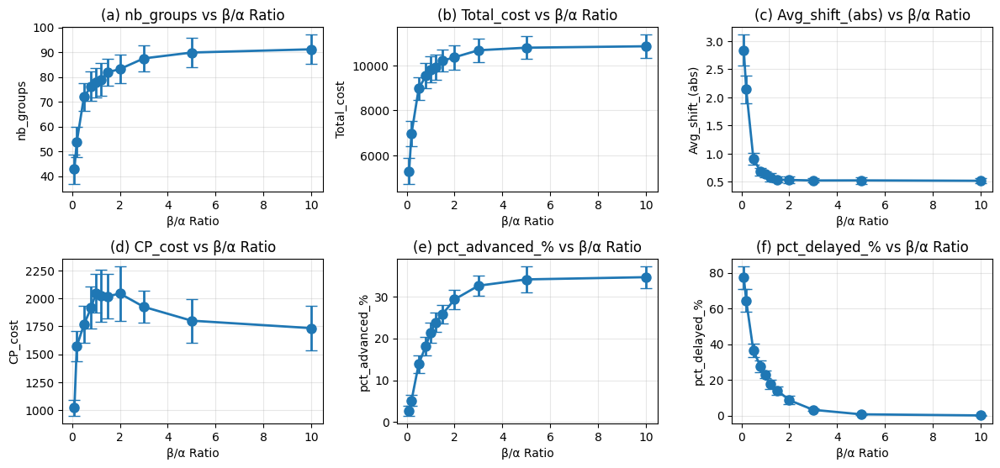

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
# 🔥 可视化汇总结果
read_summary_df = pd.read_csv('sensitivity_beta_multiplier_alpha10/summary_beta_multiplier_alpha10.csv')
plt.figure(figsize=(12, 8))
metrics_to_plot = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 'CP_cost', 'pct_advanced_%', 'pct_delayed_%']
subplot_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']  # 6个子图标签
for i, (metric, label) in enumerate(zip(metrics_to_plot, subplot_labels), 1):
    plt.subplot(3, 3, i)
    mean_vals = read_summary_df.groupby('beta_multiplier')[metric].mean()
    std_vals = read_summary_df.groupby('beta_multiplier')[metric].std()
    plt.errorbar(mean_vals.index, mean_vals.values, yerr=std_vals.values, 
                fmt='o-', capsize=5, linewidth=2, markersize=8)
    plt.title(f'{label} {metric} vs β/α Ratio')
    plt.xlabel('β/α Ratio')
    plt.ylabel(metric)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('sensitivity_beta_multiplier_alpha10/beta_multiplier_analysis.png', dpi=300, bbox_inches='tight')
plt.show()





# # 🔥 可视化汇总结果 - 添加(a)(b)(c)...子图标签
# read_summary_df = pd.read_csv('sensitivity_beta_multiplier_alpha10/summary_beta_multiplier_alpha10.csv')
# plt.figure(figsize=(12, 8))  # 增大画布适应3x3布局

# metrics_to_plot = ['nb_groups', 'Total_cost', 'Avg_shift_(abs)', 'CP_cost', 'pct_advanced_%', 'pct_delayed_%']
# subplot_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']  # 6个子图标签

# for i, (metric, label) in enumerate(zip(metrics_to_plot, subplot_labels), 1):
#     plt.subplot(2, 3, i)  # 改为3行2列布局，更紧凑
    
#     mean_vals = read_summary_df.groupby('beta_multiplier')[metric].mean()
#     std_vals = read_summary_df.groupby('beta_multiplier')[metric].std()
    
#     plt.errorbar(mean_vals.index, mean_vals.values, yerr=std_vals.values, 
#                 fmt='o-', capsize=5, linewidth=2, markersize=8, label=metric)
    
#     # 🔥 添加子图标签：标题前面加(a)(b)(c)...
#     plt.title(f'{label} {metric.replace("_", " ").title()} vs β/α Ratio', fontsize=11, fontweight='bold')
#     plt.xlabel('β/α Ratio (Multiplier)')
#     plt.ylabel(metric.replace('_', ' '))
#     plt.grid(True, alpha=0.3)
    
#     # 添加图例（可选）
#     if i == 1:  # 只在第一个子图加图例
#         plt.legend()

# plt.tight_layout()
# plt.show()

